In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path("../results")
FIGURES_DIR = Path("../figures")

df = pd.read_csv(
    RESULTS_DIR / "uber_with_clusters.csv"
)

df["Date/Time"] = pd.to_datetime(df["Date/Time"])
df["Date"] = df["Date/Time"].dt.date
df["Hour"] = df["Date/Time"].dt.hour
df["DayOfWeek"] = df["Date/Time"].dt.day_name()

print("AVAILABLE COLUMNS")
print(df.columns.tolist())

display(df.head())

AVAILABLE COLUMNS
['Date/Time', 'Lat', 'Lon', 'Base', 'Cluster', 'Date', 'Hour', 'DayOfWeek']


,Date/Time,Lat,Lon,Base,Cluster,Date,Hour,DayOfWeek
0,2014-09-01 00:01:00,40.2201,-74.0021,B02512,6,2014-09-01,0,Monday
1,2014-09-01 00:01:00,40.7500,-74.0027,B02512,2,2014-09-01,0,Monday
2,2014-09-01 00:03:00,40.7559,-73.9864,B02512,0,2014-09-01,0,Monday
3,2014-09-01 00:06:00,40.7450,-73.9889,B02512,2,2014-09-01,0,Monday
4,2014-09-01 00:11:00,40.8145,-73.9444,B02512,0,2014-09-01,0,Monday


HOURLY PICKUP COUNTS BY CLUSTER


Cluster,0,1,2,3,4,5,6
Hour,,,,,,,
0,4991,394,14052,461,566,186,3483
1,3127,216,9719,197,373,100,2375
2,2278,184,6203,115,300,37,1585
3,2938,272,5162,161,411,69,1776
4,3607,348,5044,764,508,187,2217
5,6205,506,7671,1268,843,247,3522
6,12635,701,12274,1354,1405,278,4660
7,17384,770,17295,754,1614,304,5193
8,17015,726,18669,629,2028,286,5124


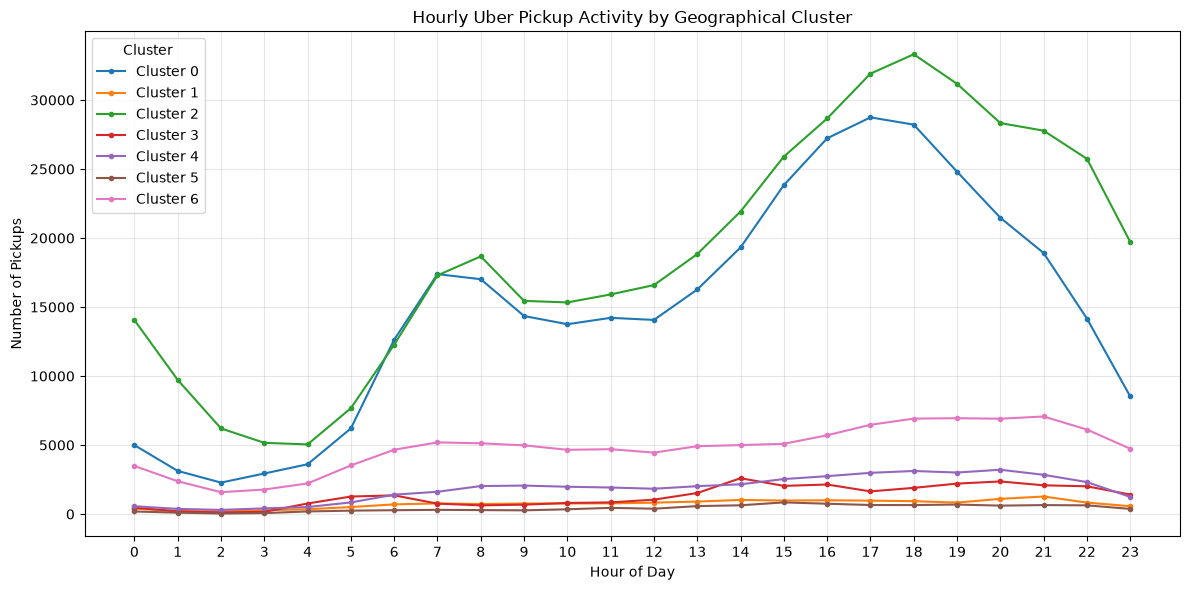

In [23]:
# Calculate hourly pickup counts for each cluster

hourly_cluster_counts = (
    df.groupby(["Hour", "Cluster"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(24), fill_value=0)
)

print("HOURLY PICKUP COUNTS BY CLUSTER")
display(hourly_cluster_counts)
hourly_cluster_counts.to_csv(
    RESULTS_DIR / "03_hourly_pickup_counts.csv"
)

# Visualise hourly pickup activity

plt.figure(figsize=(12, 6))

for cluster in hourly_cluster_counts.columns:
    plt.plot(
        hourly_cluster_counts.index,
        hourly_cluster_counts[cluster],
        marker="o",
        markersize=3,
        label=f"Cluster {cluster}"
    )

plt.title("Hourly Uber Pickup Activity by Geographical Cluster")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Pickups")
plt.xticks(range(24))
plt.legend(title="Cluster")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_hourly_pickup_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

HOURLY PICKUP DISTRIBUTION (%)


Cluster,0,1,2,3,4,5,6
Hour,,,,,,,
0,1.39,2.23,3.10,1.49,1.29,1.82,3.04
1,0.87,1.22,2.15,0.64,0.85,0.98,2.07
2,0.64,1.04,1.37,0.37,0.68,0.36,1.38
3,0.82,1.54,1.14,0.52,0.93,0.68,1.55
4,1.01,1.97,1.11,2.47,1.15,1.83,1.93
5,1.73,2.87,1.69,4.09,1.91,2.42,3.07
6,3.53,3.97,2.71,4.37,3.19,2.73,4.07
7,4.86,4.36,3.82,2.43,3.67,2.98,4.53
8,4.75,4.11,4.12,2.03,4.61,2.80,4.47


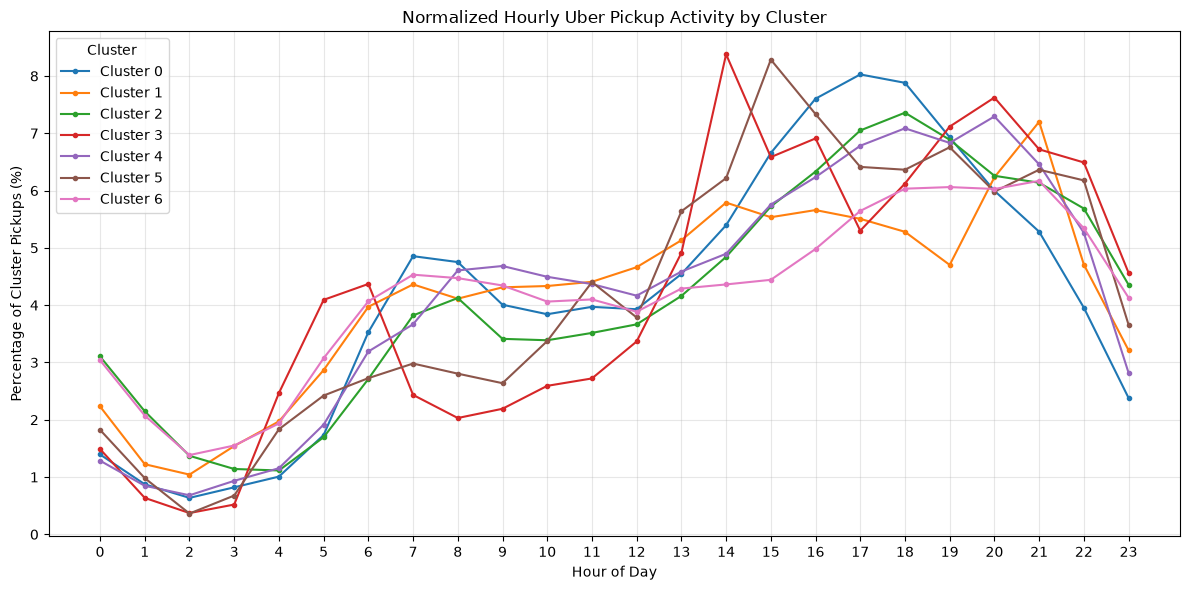

In [24]:
# Normalize hourly pickup counts within each cluster

hourly_cluster_percentages = (
    hourly_cluster_counts
    .div(hourly_cluster_counts.sum(axis=0), axis=1)
    * 100
)

print("HOURLY PICKUP DISTRIBUTION (%)")
display(hourly_cluster_percentages.round(2))
hourly_cluster_percentages.to_csv(
    RESULTS_DIR / "03_normalized_hourly_activity.csv"
)

# Compare normalized hourly patterns

plt.figure(figsize=(12, 6))

for cluster in hourly_cluster_percentages.columns:
    plt.plot(
        hourly_cluster_percentages.index,
        hourly_cluster_percentages[cluster],
        marker="o",
        markersize=3,
        label=f"Cluster {cluster}"
    )

plt.title("Normalized Hourly Uber Pickup Activity by Cluster")
plt.xlabel("Hour of Day")
plt.ylabel("Percentage of Cluster Pickups (%)")
plt.xticks(range(24))
plt.legend(title="Cluster")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_normalized_hourly_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

DAILY PICKUP COUNTS BY CLUSTER


Cluster,0,1,2,3,4,5,6
Date,,,,,,,
2014-09-01,5360,414,7336,1594,1843,445,2969
2014-09-02,10415,525,11466,1381,1834,429,2781
2014-09-03,11975,544,14255,963,1479,322,3093
2014-09-04,14277,567,17127,1035,1743,319,3292
2014-09-05,14940,647,19817,1053,1427,288,4147
2014-09-06,12010,743,19713,819,1438,237,5560
2014-09-07,8361,633,13286,1352,1763,365,4374
2014-09-08,11516,451,12727,1090,1409,332,2835
2014-09-09,13390,549,15217,731,1041,331,3301


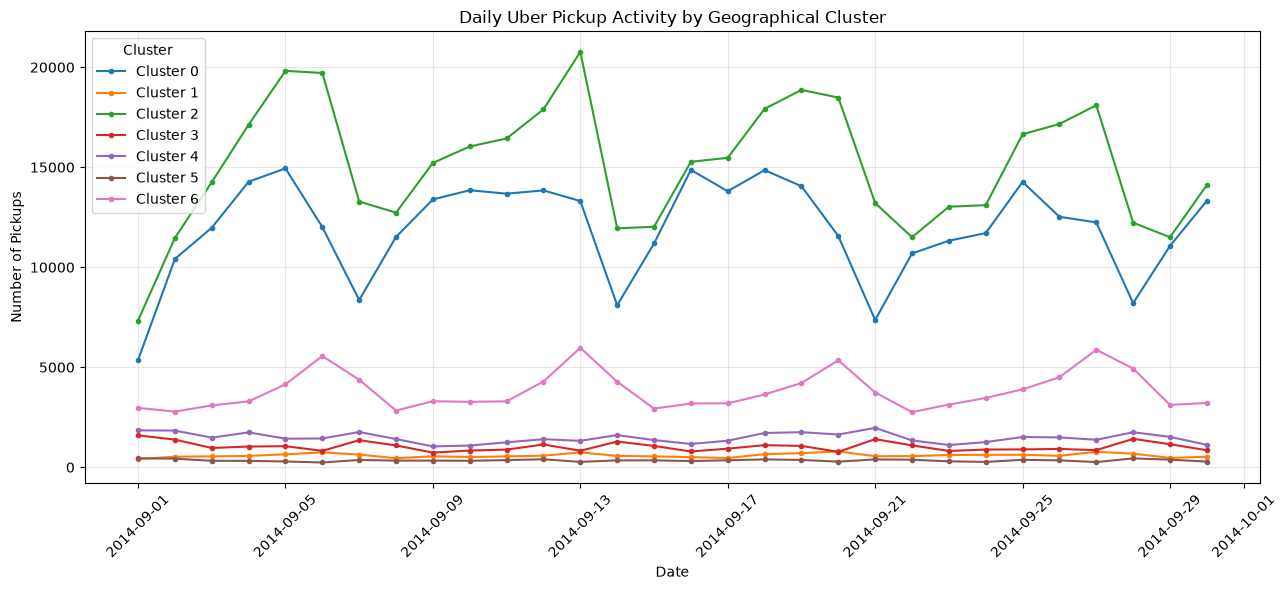

In [25]:
# Calculate daily pickup counts for each geographical cluster

daily_cluster_counts = (
    df.groupby(["Date", "Cluster"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

print("DAILY PICKUP COUNTS BY CLUSTER")
display(daily_cluster_counts)
daily_cluster_counts.to_csv(
    RESULTS_DIR / "03_daily_pickup_counts.csv"
)

# Visualize daily pickup activity

plt.figure(figsize=(13, 6))

for cluster in daily_cluster_counts.columns:
    plt.plot(
        daily_cluster_counts.index,
        daily_cluster_counts[cluster],
        marker="o",
        markersize=3,
        label=f"Cluster {cluster}"
    )

plt.title("Daily Uber Pickup Activity by Geographical Cluster")
plt.xlabel("Date")
plt.ylabel("Number of Pickups")
plt.xticks(rotation=45)
plt.legend(title="Cluster")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_daily_pickup_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

AVERAGE DAILY PICKUPS BY DAY OF WEEK AND CLUSTER


Cluster,0,1,2,3,4,5,6
DayOfWeek,,,,,,,
Monday,9964.20,486.40,11017.80,1199.00,1493.60,375.00,2921.60
Tuesday,12664.00,543.60,13818.40,913.00,1254.20,329.60,3123.20
Wednesday,12832.75,534.00,14716.50,902.75,1286.50,314.50,3256.25
Thursday,14268.75,597.00,17032.75,978.00,1553.25,359.25,3530.00
Friday,13838.25,625.00,18435.75,1043.00,1518.00,348.75,4286.25
Saturday,12280.00,761.50,19265.75,817.50,1441.75,260.75,5687.00
Sunday,8007.00,607.75,12665.50,1364.50,1772.25,385.50,4330.50


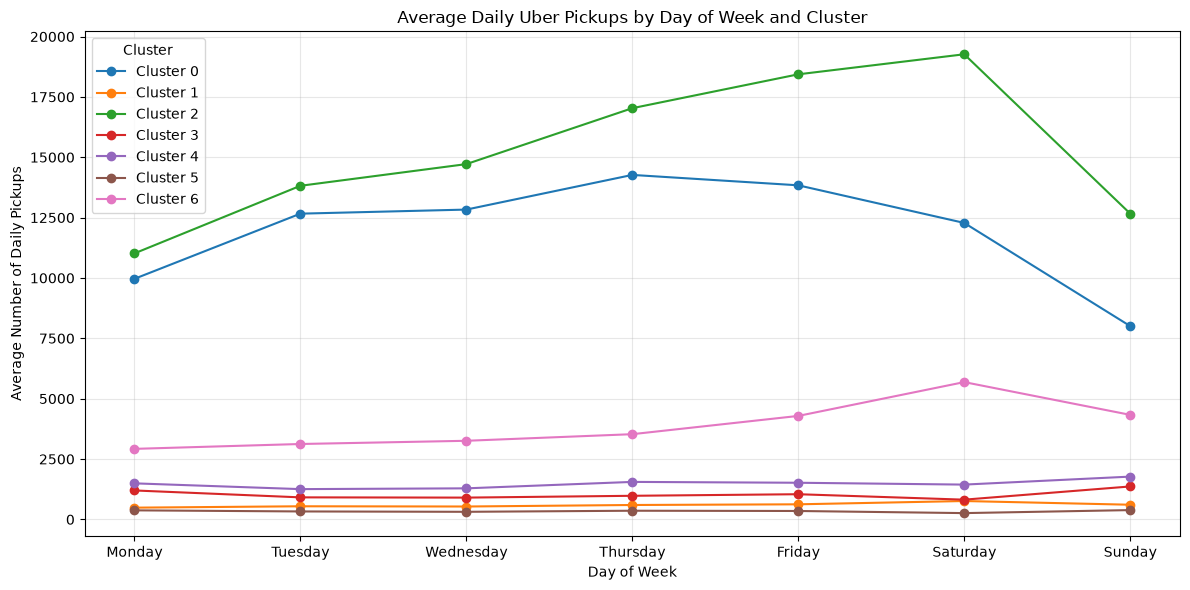

In [26]:
# Calculate average daily pickup activity by day of the week

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

daily_counts_long = (
    df.groupby(["Date", "DayOfWeek", "Cluster"])
    .size()
    .reset_index(name="Pickups")
)

weekly_cluster_counts = (
    daily_counts_long
    .groupby(["DayOfWeek", "Cluster"])["Pickups"]
    .mean()
    .unstack()
    .reindex(weekday_order)
)

print("AVERAGE DAILY PICKUPS BY DAY OF WEEK AND CLUSTER")
display(weekly_cluster_counts.round(2))
weekly_cluster_counts.to_csv(
    RESULTS_DIR / "03_weekday_average_pickups.csv"
)

# Visualize weekly pickup patterns

plt.figure(figsize=(12, 6))

for cluster in weekly_cluster_counts.columns:
    plt.plot(
        weekly_cluster_counts.index,
        weekly_cluster_counts[cluster],
        marker="o",
        label=f"Cluster {cluster}"
    )

plt.title("Average Daily Uber Pickups by Day of Week and Cluster")
plt.xlabel("Day of Week")
plt.ylabel("Average Number of Daily Pickups")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "03_weekday_average_pickups.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

DAILY GEOGRAPHICAL PICKUP CENTRES


,Date,Cluster,Lat,Lon
0,2014-09-01,0,40.770358,-73.970999
1,2014-09-01,1,40.876754,-73.897132
2,2014-09-01,2,40.730508,-73.993135
3,2014-09-01,3,40.656618,-73.766617
4,2014-09-01,4,40.762700,-73.868451
5,2014-09-01,5,40.693146,-74.190114
6,2014-09-01,6,40.679058,-73.961812
7,2014-09-02,0,40.766953,-73.972439
8,2014-09-02,1,40.879206,-73.902797
9,2014-09-02,2,40.730385,-73.994883


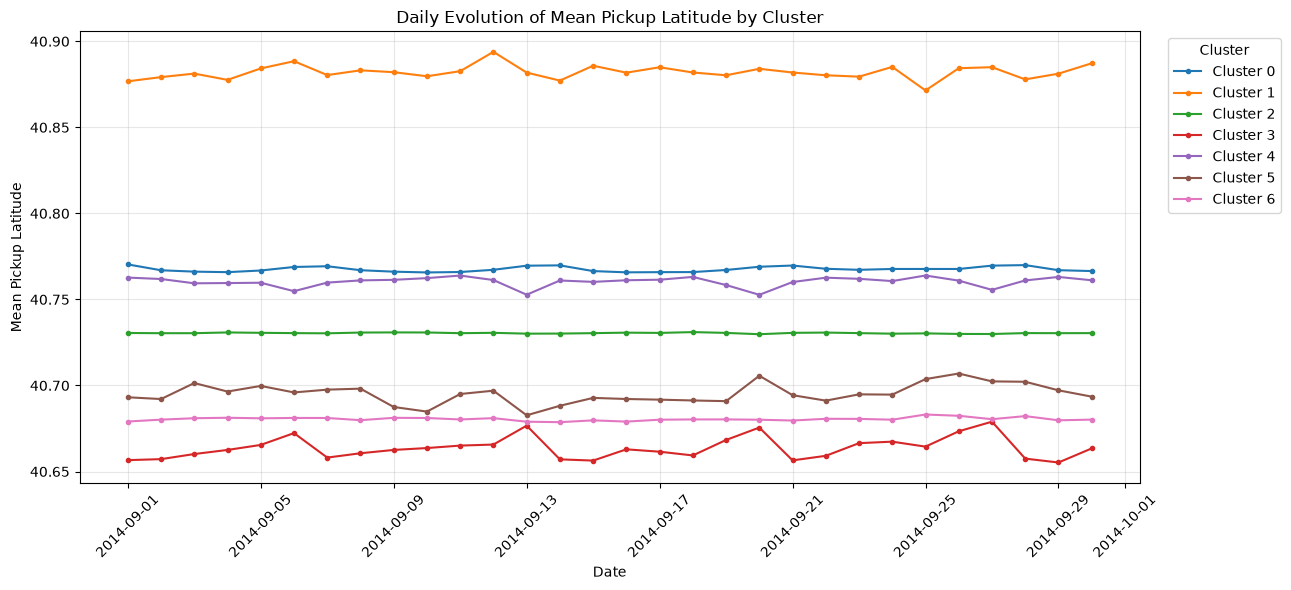

In [27]:
# Calculate daily geographical centres of pickup activity

daily_centres = (
    df.groupby(["Date", "Cluster"])[["Lat", "Lon"]]
    .mean()
    .reset_index()
)

print("DAILY GEOGRAPHICAL PICKUP CENTRES")
display(daily_centres.head(14))
daily_centres.to_csv(
    RESULTS_DIR / "03_daily_geographical_centres.csv",
    index=False
)

# Visualize daily changes in mean pickup latitude

plt.figure(figsize=(13, 6))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = daily_centres[
        daily_centres["Cluster"] == cluster
    ]

    plt.plot(
        cluster_data["Date"],
        cluster_data["Lat"],
        marker="o",
        markersize=3,
        label=f"Cluster {cluster}"
    )

plt.title("Daily Evolution of Mean Pickup Latitude by Cluster")
plt.xlabel("Date")
plt.ylabel("Mean Pickup Latitude")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1))
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "03_daily_mean_latitude.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

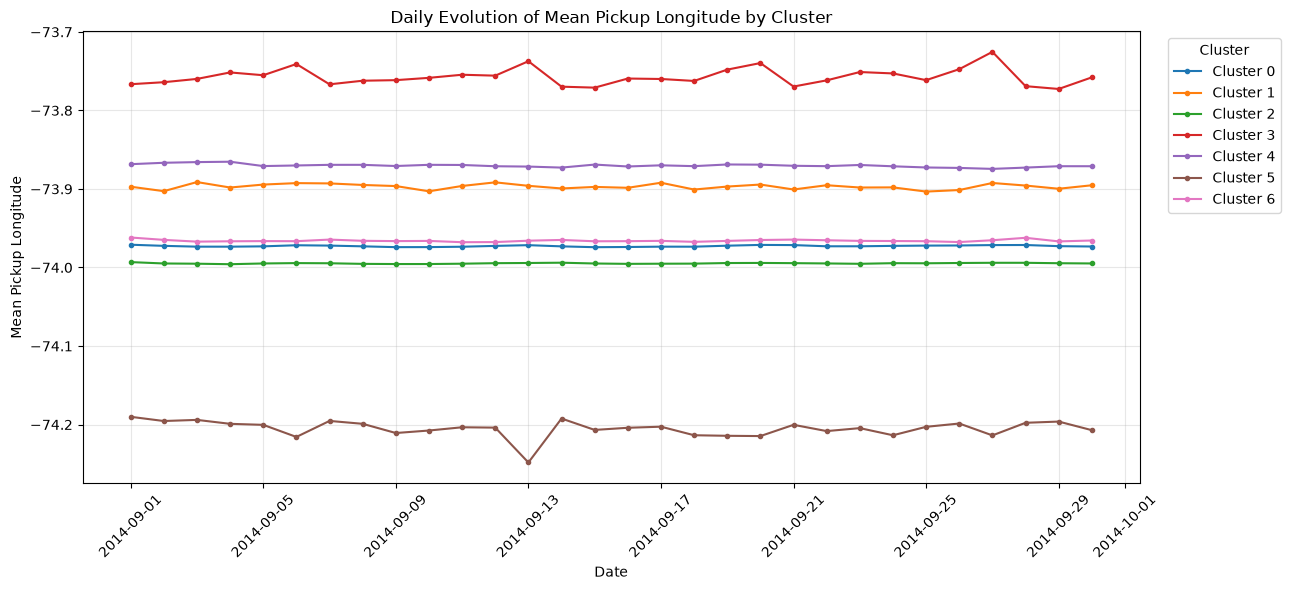

In [28]:
# Visualize daily changes in mean pickup longitude

plt.figure(figsize=(13, 6))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = daily_centres[
        daily_centres["Cluster"] == cluster
    ]

    plt.plot(
        cluster_data["Date"],
        cluster_data["Lon"],
        marker="o",
        markersize=3,
        label=f"Cluster {cluster}"
    )

plt.title("Daily Evolution of Mean Pickup Longitude by Cluster")
plt.xlabel("Date")
plt.ylabel("Mean Pickup Longitude")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1))
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "03_daily_mean_longitude.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
